## Load the DataSet

In [2]:
import sys
print("Python being used:", sys.executable)


Python being used: c:\Users\User\AppData\Local\Programs\Python\Python312\python.exe


In [4]:
%pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(
    "../data/raw/SeoulBikeData.csv",
    encoding="ISO-8859-1"
)


# Display first observations
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [7]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Dataset information
df.info()

# Statistical summary
df.describe(include="all")

Dataset shape: (8760, 14)

Columns:
['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']

Data types:
Date                          object
Rented Bike Count              int64
Hour                           int64
Temperature(°C)              float64
Humidity(%)                    int64
Wind speed (m/s)             float64
Visibility (10m)               int64
Dew point temperature(°C)    float64
Solar Radiation (MJ/m2)      float64
Rainfall(mm)                 float64
Snowfall (cm)                float64
Seasons                       object
Holiday                       object
Functioning Day               object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------   

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760,8760,8760
unique,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,2,2
top,30/11/2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,No Holiday,Yes
freq,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2208,8328,8465
mean,NaN,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068,NaN,NaN,NaN
std,NaN,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746,NaN,NaN,NaN
min,NaN,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,NaN,NaN,NaN


In [8]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check unique values
print("\nUnique values:")
print(df.nunique())

Missing values:
Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

Duplicate rows:
0

Unique values:
Date                          365
Rented Bike Count            2166
Hour                           24
Temperature(°C)               546
Humidity(%)                    90
Wind speed (m/s)               65
Visibility (10m)             1789
Dew point temperature(°C)     556
Solar Radiation (MJ/m2)       345
Rainfall(mm)                   61
Snowfall (cm)                  51
Seasons                         4
Holiday                         2
Functioning Day                 2
dtype: int64


In [9]:
# Descriptive statistics of our target
df["Rented Bike Count"].describe()

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64

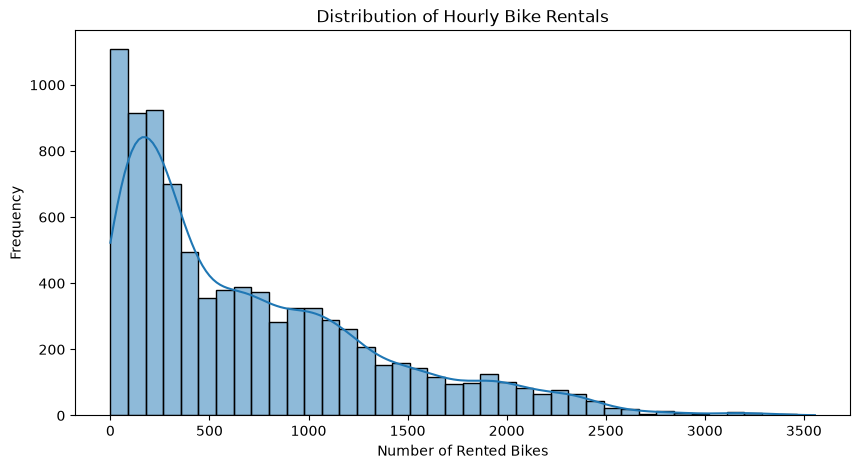

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Rented Bike Count"],
    bins=40,
    kde=True
)

plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Number of Rented Bikes")
plt.ylabel("Frequency")

plt.show()

In [12]:
print(df["Functioning Day"].value_counts())

print("\nRental statistics by functioning day:")

print(
    df.groupby("Functioning Day")["Rented Bike Count"]
    .agg(["count", "mean", "min", "max"])
)

Functioning Day
Yes    8465
No      295
Name: count, dtype: int64

Rental statistics by functioning day:
                 count        mean  min   max
Functioning Day                              
No                 295    0.000000    0     0
Yes               8465  729.156999    2  3556


In [13]:
print("Total zero-rental observations:",
      (df["Rented Bike Count"] == 0).sum())

print("\nZero rentals by functioning day:")

print(
    df[df["Rented Bike Count"] == 0]
    ["Functioning Day"]
    .value_counts()
)

Total zero-rental observations: 295

Zero rentals by functioning day:
Functioning Day
No    295
Name: count, dtype: int64


In [15]:
# Make sure Date is datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)

# Extract weekday name
df["Weekday"] = df["Date"].dt.day_name()

print(df[["Date", "Weekday"]].head())

        Date Weekday
0 2017-12-01  Friday
1 2017-12-01  Friday
2 2017-12-01  Friday
3 2017-12-01  Friday
4 2017-12-01  Friday


In [16]:
weekday = df.groupby("Weekday")["Rented Bike Count"].mean()

# Display in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday = weekday.reindex(weekday_order)

print("Average rentals by weekday:")
print(weekday.round(2).to_string())

Average rentals by weekday:
Weekday
Monday       730.56
Tuesday      687.98
Wednesday    740.35
Thursday     690.70
Friday       747.12
Saturday     709.53
Sunday       625.16


In [17]:
hourly = df.groupby("Hour")["Rented Bike Count"].mean()

print("Average rentals by hour:")
print(hourly.round(2).to_string())

print("\nHighest-demand hour:", hourly.idxmax())
print("Lowest-demand hour:", hourly.idxmin())

Average rentals by hour:
Hour
0      541.46
1      426.18
2      301.63
3      203.33
4      132.59
5      139.08
6      287.56
7      606.01
8     1015.70
9      645.98
10     527.82
11     600.85
12     699.44
13     733.25
14     758.82
15     829.19
16     930.62
17    1138.51
18    1502.93
19    1195.15
20    1068.96
21    1031.45
22     922.80
23     671.13

Highest-demand hour: 18
Lowest-demand hour: 4


In [18]:
# Create a copy to preserve our original dataset
ts_df = df.copy()

# Ensure Date is in datetime format
ts_df["Date"] = pd.to_datetime(
    ts_df["Date"],
    format="%d/%m/%Y"
)

# Combine Date and Hour into one timestamp
ts_df["DateTime"] = (
    ts_df["Date"] +
    pd.to_timedelta(ts_df["Hour"], unit="h")
)

# Sort observations chronologically
ts_df = ts_df.sort_values("DateTime")

# Display results
print(ts_df[["Date", "Hour", "DateTime"]].head(10))

        Date  Hour            DateTime
0 2017-12-01     0 2017-12-01 00:00:00
1 2017-12-01     1 2017-12-01 01:00:00
2 2017-12-01     2 2017-12-01 02:00:00
3 2017-12-01     3 2017-12-01 03:00:00
4 2017-12-01     4 2017-12-01 04:00:00
5 2017-12-01     5 2017-12-01 05:00:00
6 2017-12-01     6 2017-12-01 06:00:00
7 2017-12-01     7 2017-12-01 07:00:00
8 2017-12-01     8 2017-12-01 08:00:00
9 2017-12-01     9 2017-12-01 09:00:00


In [19]:
# Check duplicate timestamps
print(
    "Duplicate timestamps:",
    ts_df.index.duplicated().sum()
)

# Check time differences between observations
time_differences = ts_df.index.to_series().diff().dropna()

print("\nTime differences:")
print(time_differences.value_counts())

# Check expected frequency
expected_index = pd.date_range(
    start=ts_df.index.min(),
    end=ts_df.index.max(),
    freq="h"
)

print("\nExpected observations:", len(expected_index))
print("Actual observations:", len(ts_df))
print("Missing timestamps:", len(expected_index.difference(ts_df.index)))

Duplicate timestamps: 0

Time differences:
1.0    8759
Name: count, dtype: int64

Expected observations: 1
Actual observations: 8760
Missing timestamps: 1


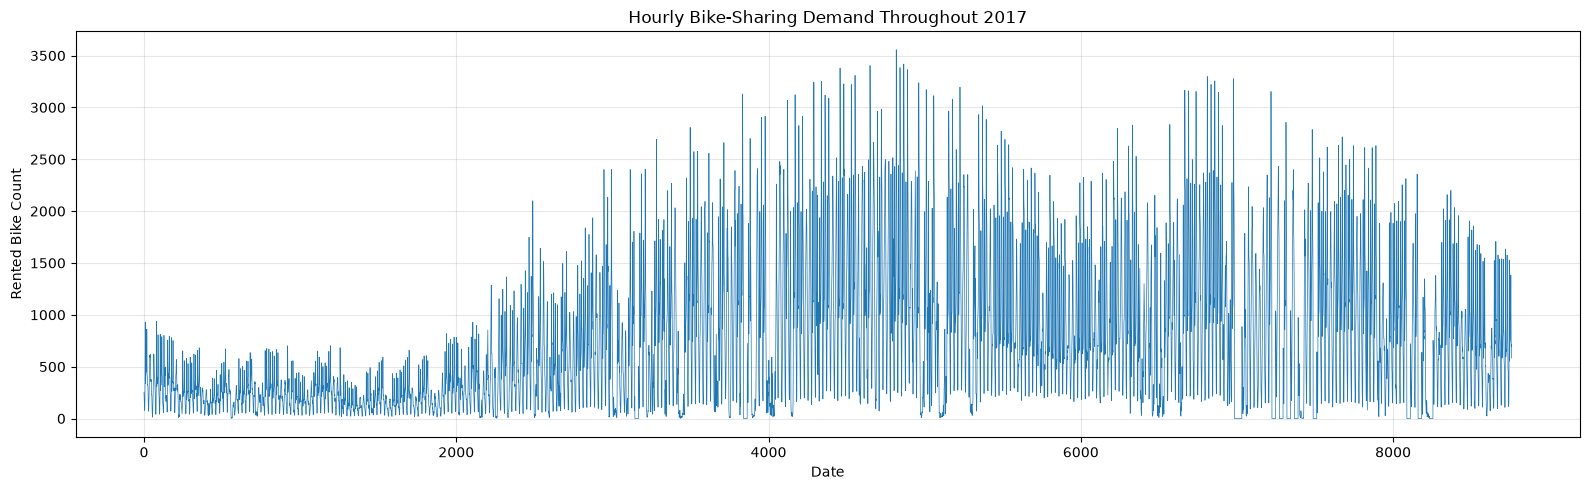

In [21]:
plt.figure(figsize=(16, 5))

plt.plot(
    ts_df.index,
    ts_df["Rented Bike Count"],
    linewidth=0.5
)

plt.title("Hourly Bike-Sharing Demand Throughout 2017")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/full_time_series.png",
    dpi=300
)

plt.show()

In [24]:
print("First timestamp:", ts_df.index.min())
print("Last timestamp:", ts_df.index.max())

expected_index = pd.date_range(
    start=ts_df.index.min(),
    end=ts_df.index.max(),
    freq="h"
)

print("Expected observations:", len(expected_index))
print("Actual observations:", len(ts_df))
print("Missing timestamps:", len(expected_index.difference(ts_df.index)))

First timestamp: 2017-12-01 00:00:00
Last timestamp: 2018-11-30 23:00:00
Expected observations: 8760
Actual observations: 8760
Missing timestamps: 0


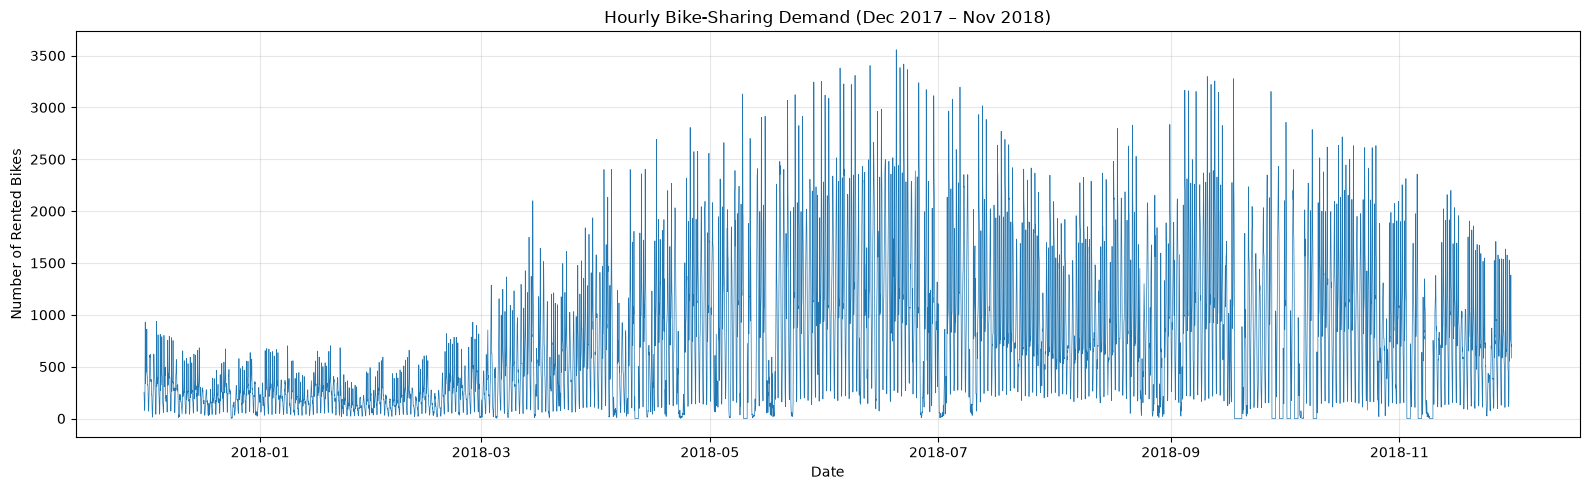

In [25]:
plt.figure(figsize=(16, 5))

plt.plot(
    ts_df.index,
    ts_df["Rented Bike Count"],
    linewidth=0.5
)

plt.title("Hourly Bike-Sharing Demand (Dec 2017 – Nov 2018)")
plt.xlabel("Date")
plt.ylabel("Number of Rented Bikes")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/full_time_series.png",
    dpi=300
)

plt.show()

In [26]:
monthly_demand = ts_df["Rented Bike Count"].resample("ME").mean()

print("Average hourly rentals by month:")
print(monthly_demand.round(2))

Average hourly rentals by month:
DateTime
2017-12-31     249.10
2018-01-31     201.62
2018-02-28     225.94
2018-03-31     511.55
2018-04-30     728.09
2018-05-31     950.39
2018-06-30    1245.68
2018-07-31     987.18
2018-08-31     876.19
2018-09-30     935.57
2018-10-31     874.56
2018-11-30     646.83
Freq: ME, Name: Rented Bike Count, dtype: float64


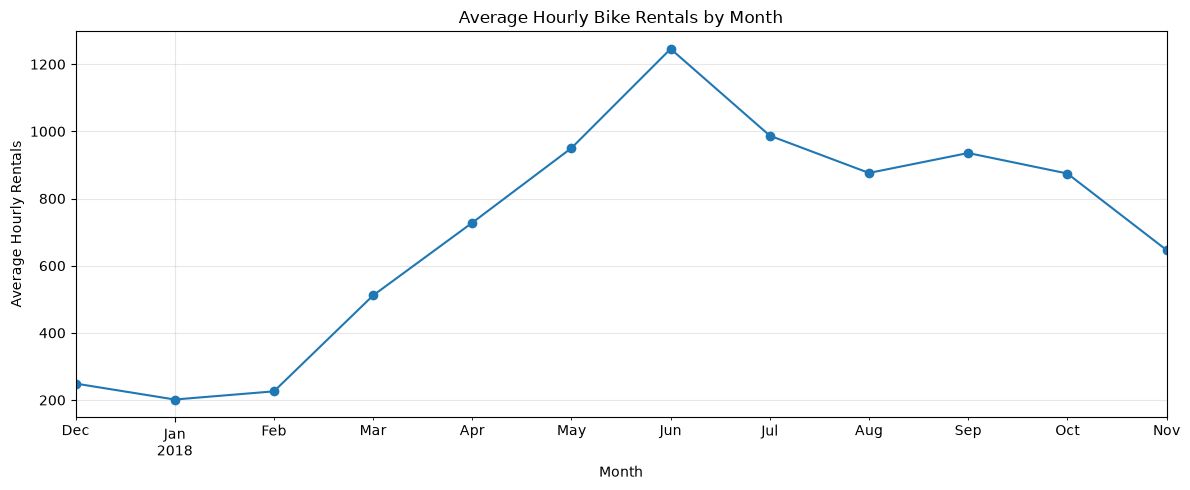

In [27]:
plt.figure(figsize=(12, 5))

monthly_demand.plot(marker="o")

plt.title("Average Hourly Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Hourly Rentals")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/monthly_demand.png",
    dpi=300
)

plt.show()

In [28]:
# Keep only observations when the system was functioning
operating_df = ts_df[ts_df["Functioning Day"] == "Yes"]

# Calculate monthly average rentals during operating hours
monthly_operating_demand = (
    operating_df["Rented Bike Count"].resample("ME").mean()
)

print("Monthly average rentals (operating hours only):")
print(monthly_operating_demand.round(2))

Monthly average rentals (operating hours only):
DateTime
2017-12-31     249.10
2018-01-31     201.62
2018-02-28     225.94
2018-03-31     511.55
2018-04-30     753.20
2018-05-31     982.07
2018-06-30    1245.68
2018-07-31     987.18
2018-08-31     876.19
2018-09-30    1079.51
2018-10-31     978.46
2018-11-30     718.70
Freq: ME, Name: Rented Bike Count, dtype: float64


In [29]:
monthly_comparison = pd.DataFrame({
    "All Hours": monthly_demand,
    "Operating Hours Only": monthly_operating_demand
})

print(monthly_comparison.round(2))

            All Hours  Operating Hours Only
DateTime                                   
2017-12-31     249.10                249.10
2018-01-31     201.62                201.62
2018-02-28     225.94                225.94
2018-03-31     511.55                511.55
2018-04-30     728.09                753.20
2018-05-31     950.39                982.07
2018-06-30    1245.68               1245.68
2018-07-31     987.18                987.18
2018-08-31     876.19                876.19
2018-09-30     935.57               1079.51
2018-10-31     874.56                978.46
2018-11-30     646.83                718.70


In [30]:
import os

os.makedirs("../results/tables", exist_ok=True)

monthly_comparison.to_csv(
    "../results/tables/monthly_demand_comparison.csv"
)

In [31]:
hourly_demand = (
    operating_df.groupby(operating_df.index.hour)["Rented Bike Count"]
    .mean()
)

print("Average rentals by hour (operating hours only):")
print(hourly_demand.round(2))

Average rentals by hour (operating hours only):
DateTime
0      561.46
1      441.92
2      312.77
3      210.84
4      137.49
5      144.22
6      298.18
7      626.61
8     1050.23
9      667.94
10     545.76
11     621.28
12     723.22
13     758.17
14     784.62
15     857.37
16     962.26
17    1177.21
18    1554.02
19    1235.78
20    1105.30
21    1066.51
22     954.17
23     693.94
Name: Rented Bike Count, dtype: float64


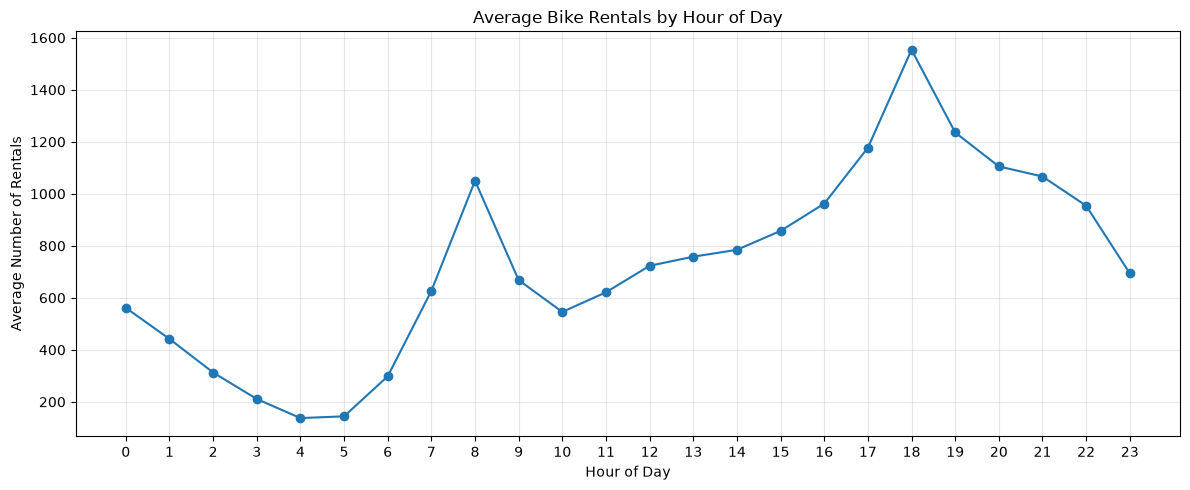

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/hourly_demand.png",
    dpi=300
)

plt.show()

In [33]:
hourly_demand.to_csv(
    "../results/tables/hourly_demand.csv",
    header=["Average Rentals"]
)

In [34]:
weekday_demand = (
    operating_df.groupby(operating_df.index.day_name())["Rented Bike Count"]
    .mean()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = weekday_demand.reindex(weekday_order)

print("Average rentals by weekday (operating hours only):")
print(weekday_demand.round(2))

Average rentals by weekday (operating hours only):
DateTime
Monday       730.56
Tuesday      745.31
Wednesday    769.96
Thursday     718.33
Friday       776.42
Saturday     727.60
Sunday       637.41
Name: Rented Bike Count, dtype: float64


In [35]:
weekday_demand.to_csv(
    "../results/tables/weekday_demand.csv",
    header=["Average Rentals"]
)

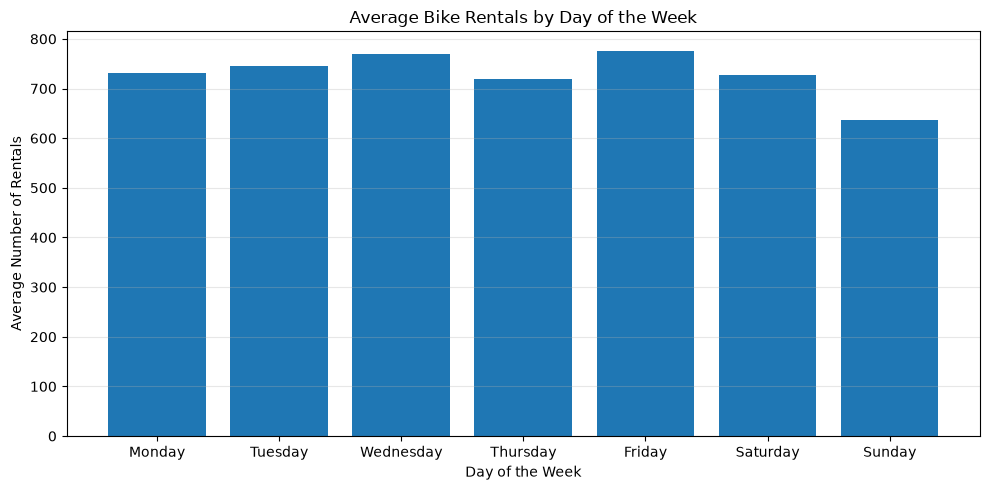

In [36]:
plt.figure(figsize=(10, 5))

plt.bar(weekday_demand.index, weekday_demand.values)

plt.title("Average Bike Rentals by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Number of Rentals")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/weekday_demand.png",
    dpi=300
)

plt.show()

In [37]:
# Calculate average rentals for each weekday and hour
weekday_hour = operating_df.pivot_table(
    values="Rented Bike Count",
    index=operating_df.index.day_name(),
    columns=operating_df.index.hour,
    aggfunc="mean"
)

# Arrange weekdays in calendar order
weekday_hour = weekday_hour.reindex(weekday_order)

print(weekday_hour.round(2))

DateTime       0       1       2       3       4       5       6       7   \
DateTime                                                                    
Monday     459.58  296.17  199.87  132.77  103.15  157.42  370.35  797.48   
Tuesday    512.92  412.08  282.04  184.94  124.69  152.48  362.69  817.79   
Wednesday  526.06  412.02  288.52  199.50  131.76  147.34  333.98  756.56   
Thursday   540.86  431.38  301.04  191.68  123.70  148.02  333.96  733.20   
Friday     549.88  448.61  298.39  200.37  130.43  153.37  360.02  783.57   
Saturday   690.10  621.06  456.56  311.78  192.22  144.40  194.04  300.92   
Sunday     651.37  475.96  365.49  256.24  157.08  106.86  134.00  209.25   

DateTime        8       9   ...      14       15       16       17       18  \
DateTime                    ...                                               
Monday     1268.90  703.81  ...  712.54   782.63   908.27  1173.17  1695.00   
Tuesday    1382.67  775.10  ...  723.48   760.12   884.65  1142.40  1

In [38]:
weekday_hour.to_csv(
    "../results/tables/weekday_hour_demand.csv"
)

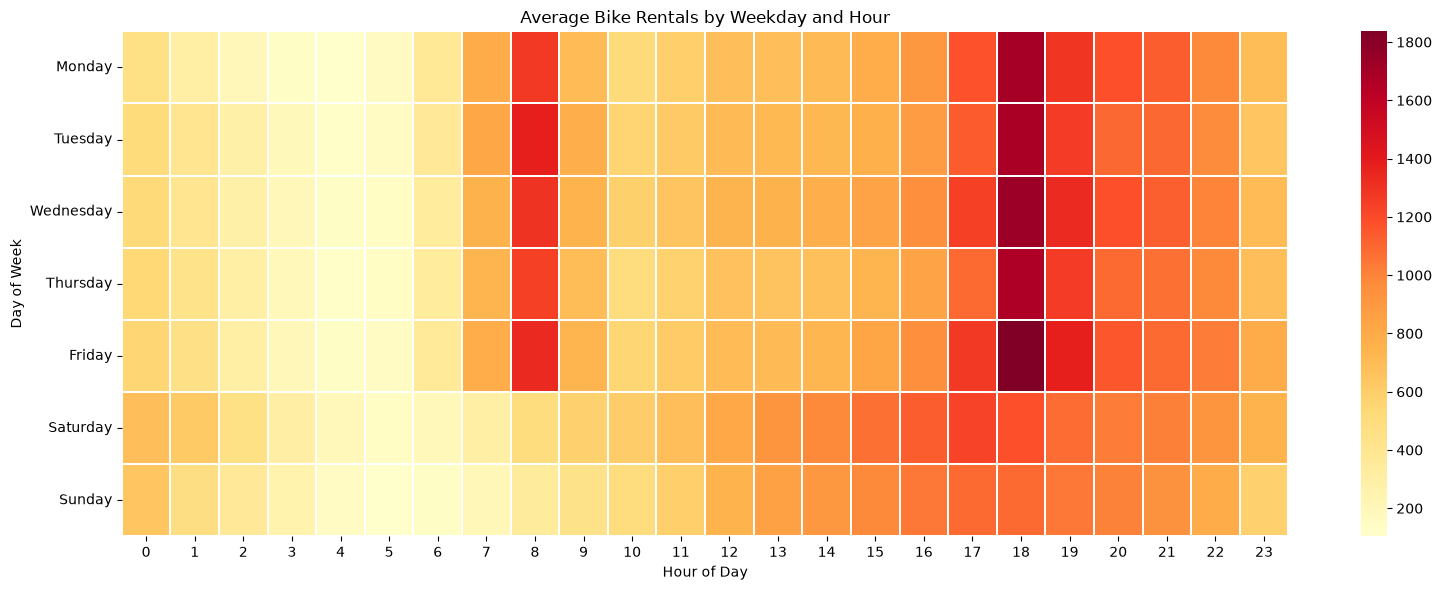

In [39]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    weekday_hour,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3
)

plt.title("Average Bike Rentals by Weekday and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()

plt.savefig(
    "../results/figures/weekday_hour_heatmap.png",
    dpi=300
)

plt.show()

In [40]:
# Find the hour with the highest average rentals for each weekday
peak_hour = weekday_hour.idxmax(axis=1)

# Find the corresponding rental average
peak_demand = weekday_hour.max(axis=1)

peak_summary = pd.DataFrame({
    "Peak Hour": peak_hour,
    "Average Rentals": peak_demand
})

print(peak_summary.round(2))

           Peak Hour  Average Rentals
DateTime                             
Monday            18          1695.00
Tuesday           18          1681.71
Wednesday         18          1734.82
Thursday          18          1669.18
Friday            18          1836.76
Saturday          17          1232.41
Sunday            17          1089.61


In [42]:
morning_demand = weekday_hour.loc[:, 7:9].mean(axis=1)

evening_demand = weekday_hour.loc[:, 17:20].mean(axis=1)

peak_comparison = pd.DataFrame({
    "Morning (07:00-09:00)": morning_demand,
    "Evening (17:00-20:00)": evening_demand
})

print(peak_comparison.round(2).to_string())

           Morning (07:00-09:00)  Evening (17:00-20:00)
DateTime                                               
Monday                    923.40                1335.98
Tuesday                   991.85                1296.09
Wednesday                 936.06                1371.84
Thursday                  891.94                1277.60
Friday                    952.55                1409.56
Saturday                  458.71                1130.88
Sunday                    331.42                1057.14


In [43]:
peak_comparison.to_csv(
    "../results/tables/morning_evening_comparison.csv"
)

Skewness: 1.1534281773679014
Kurtosis: 0.8533869902003848


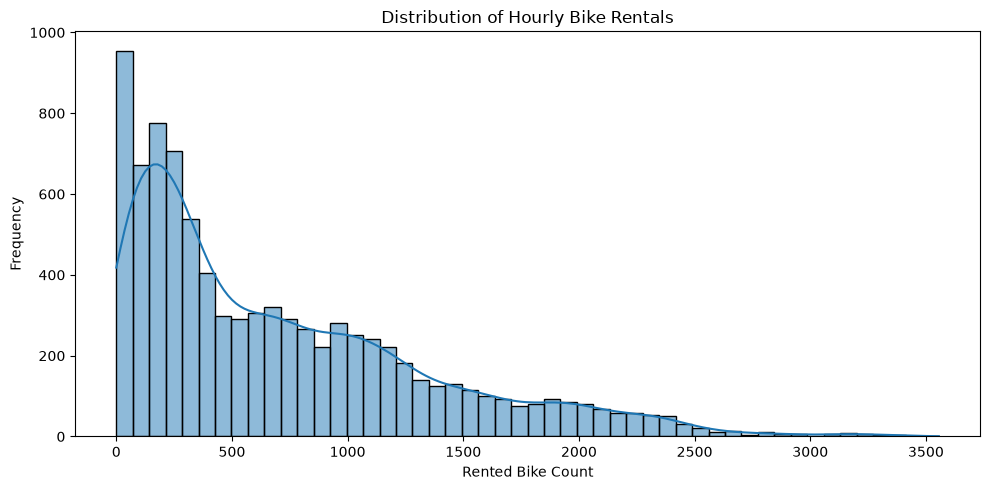

In [44]:
print("Skewness:", ts_df["Rented Bike Count"].skew())
print("Kurtosis:", ts_df["Rented Bike Count"].kurtosis())

plt.figure(figsize=(10, 5))
sns.histplot(ts_df["Rented Bike Count"], bins=50, kde=True)

plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("../results/figures/demand_distribution.png", dpi=300)
plt.show()

In [45]:
weather_columns = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)"
]

correlations = (
    ts_df[["Rented Bike Count"] + weather_columns]
    .corr()["Rented Bike Count"]
    .drop("Rented Bike Count")
    .sort_values(ascending=False)
)

print(correlations.round(3))

Temperature(°C)              0.539
Dew point temperature(°C)    0.380
Solar Radiation (MJ/m2)      0.262
Visibility (10m)             0.199
Wind speed (m/s)             0.121
Rainfall(mm)                -0.123
Snowfall (cm)               -0.142
Humidity(%)                 -0.200
Name: Rented Bike Count, dtype: float64


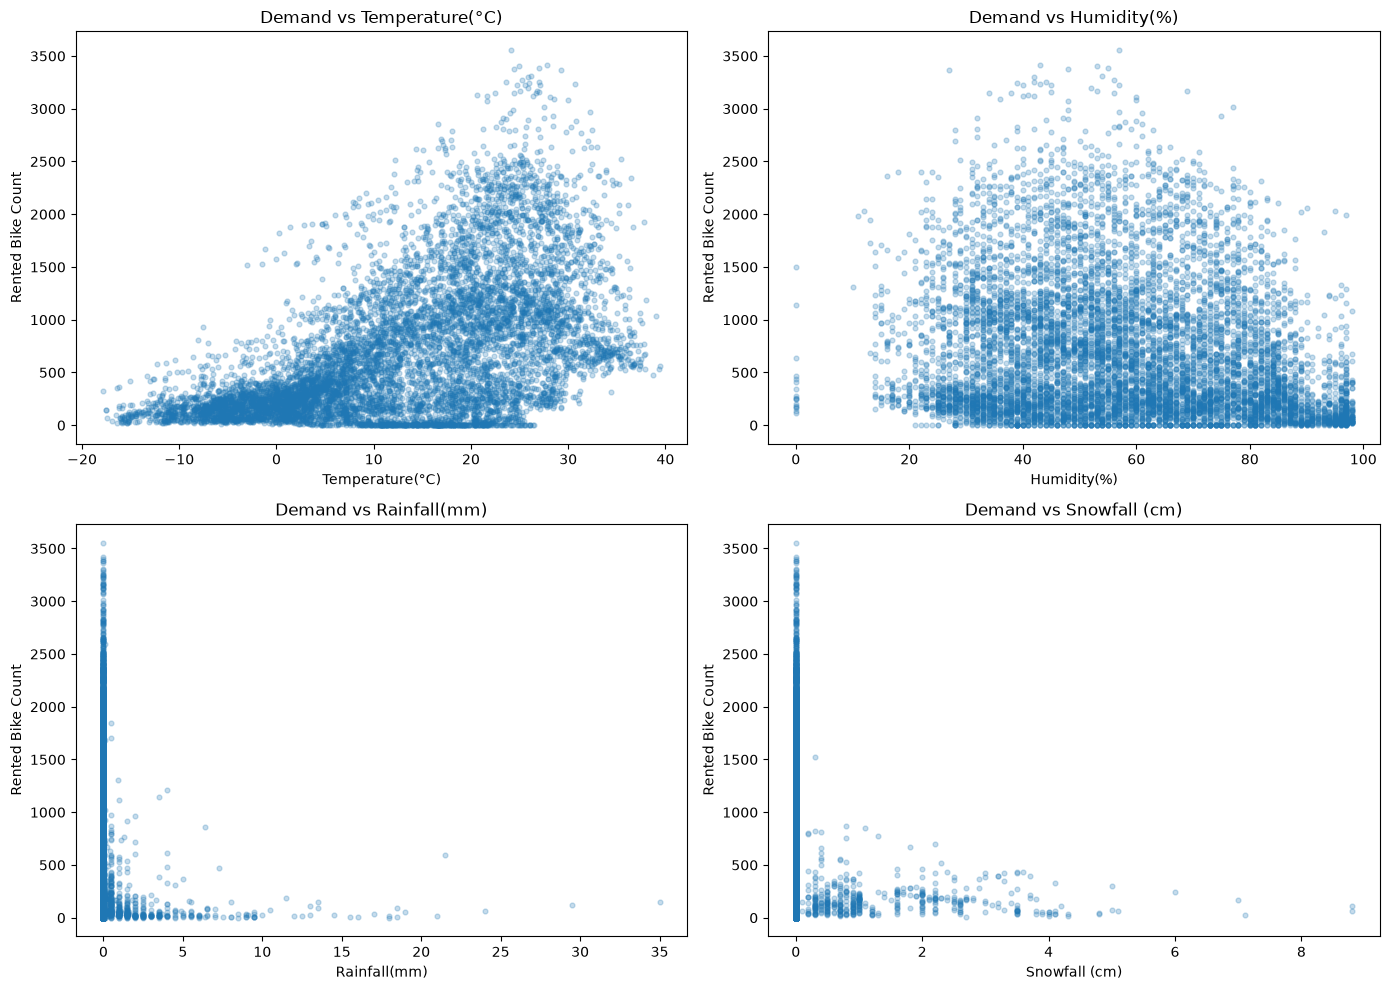

In [46]:
import matplotlib.pyplot as plt

weather_to_plot = [
    "Temperature(°C)",
    "Humidity(%)",
    "Rainfall(mm)",
    "Snowfall (cm)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), weather_to_plot):
    ax.scatter(
        ts_df[column],
        ts_df["Rented Bike Count"],
        alpha=0.25,
        s=12
    )
    ax.set_xlabel(column)
    ax.set_ylabel("Rented Bike Count")
    ax.set_title(f"Demand vs {column}")

plt.tight_layout()

plt.savefig(
    "../results/figures/weather_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
for column in weather_to_plot:
    print(f"\n{column}")
    print("Correlation:", round(
        ts_df[column].corr(ts_df["Rented Bike Count"]), 3
    ))
    print("Minimum:", ts_df[column].min())
    print("Maximum:", ts_df[column].max())


Temperature(°C)
Correlation: 0.539
Minimum: -17.8
Maximum: 39.4

Humidity(%)
Correlation: -0.2
Minimum: 0
Maximum: 98

Rainfall(mm)
Correlation: -0.123
Minimum: 0.0
Maximum: 35.0

Snowfall (cm)
Correlation: -0.142
Minimum: 0.0
Maximum: 8.8


In [48]:
ts_df["Temperature Group"] = pd.cut(
    ts_df["Temperature(°C)"],
    bins=5
)

temperature_demand = (
    ts_df.groupby("Temperature Group", observed=False)["Rented Bike Count"]
    .agg(["count", "mean"])
)

print(temperature_demand.round(2).to_string())

                   count     mean
Temperature Group                
(-17.857, -6.36]     529   164.81
(-6.36, 5.08]       1989   278.71
(5.08, 16.52]       2428   613.92
(16.52, 27.96]      2923  1036.75
(27.96, 39.4]        891  1133.26


In [49]:
temperature_demand.to_csv(
    "../results/tables/temperature_demand.csv"
)